# Section 2 · Task 2.2 — Visualize Quantum Measurements

**Exam:** C1000-179 *Fundamentals of Quantum Computing Using Qiskit v2.X Developer*
**Section 2:** Visualize quantum circuits, measurements, and states (≈ 11 % of the exam) → **Task 2.2: Visualize quantum measurements**
**Official references from the study guide:**
- [Classical feedforward and control flow (dynamic circuits)](https://quantum.cloud.ibm.com/docs/en/guides/classical-feedforward-and-control-flow)
- [`qiskit.visualization` module](https://quantum.cloud.ibm.com/docs/en/api/qiskit/visualization)
- [`plot_gate_map`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.plot_gate_map)

---

### IBM's self-test applied here
1. **How** do measurements appear in a circuit, how do results come back, and how do you plot them (histograms, hardware maps, dynamic-circuit diagrams)?
2. **Why** do we visualise *distributions* rather than single outcomes — what do the bars really estimate, and how noisy are they?
3. **What goes wrong** if you misread them? (classical-bit order in bit-strings, counts vs probabilities, `number_to_keep` hiding data, expecting a reference sampler to run control flow …)

### What you will be able to do afterwards
- Read where each measurement writes (**classical register, bit index**) and predict the counts key
- Pull counts out of a primitive result (`PubResult → DataBin → BitArray`) and plot them with `plot_histogram` / `plot_distribution`, using **every** parameter
- Explain and quantify **shot noise** (and why 10 shots lie)
- Visualise measurements in **other bases** and relate them to Pauli expectations (Task 1.1)
- Draw and run **dynamic circuits** (`if_test`, `switch`, loops) — mid-circuit measurement and feedforward
- Use **`plot_gate_map`**, `plot_coupling_map`, `plot_error_map`, `plot_circuit_layout` to see *where* on hardware measurements happen and how reliable they are

Exercise cells are stubs returning `None`, so the notebook runs end-to-end without your answers. **Solutions are at the end.**

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector, Pauli
from qiskit.visualization import (
    plot_histogram, plot_distribution, plot_gate_map, plot_coupling_map,
    plot_error_map, plot_circuit_layout,
)
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit_aer.primitives import SamplerV2 as AerSampler

print("qiskit", qiskit.__version__)

def _todo(name):
    print(f"⏳ {name}: not attempted yet — fill in the TODO above and re-run this cell.")

qiskit 2.6.1


---
## 1 · How a measurement shows up in a circuit

A **measurement** is an instruction `measure(qubit → classical bit)`. It is **irreversible**: it projects the qubit onto $|0\rangle$ or $|1\rangle$ (Born rule) and writes the outcome into a classical bit.

| Call | What it does |
|---|---|
| `qc.measure(q, c)` | measure qubit(s) `q` into classical bit(s) `c` (broadcasts like gates) |
| `qc.measure_all()` | add a **barrier**, then a **new classical register named `meas`**, then measure every qubit into it |
| `qc.measure_all(add_bits=False)` | measure every qubit into **existing** classical bits (needs `num_clbits ≥ num_qubits`) |
| `qc.measure_active()` | like `measure_all` but only qubits that have gates on them |
| `qc.remove_final_measurements()` | strip trailing measurements (and now-unused classical bits) |

In [2]:
a = QuantumCircuit(3)
a.h(0); a.cx(0, 1)
a.measure_all()                     # adds register 'meas'
print(a)
print("classical registers:", a.cregs)
print()

b = QuantumCircuit(3, 3)            # we bring our own register 'c'
b.h(0); b.cx(0, 1)
b.measure_all(add_bits=False)       # re-use 'c'
print(b)
print("classical registers:", b.cregs)

        ┌───┐      ░ ┌─┐      
   q_0: ┤ H ├──■───░─┤M├──────
        └───┘┌─┴─┐ ░ └╥┘┌─┐   
   q_1: ─────┤ X ├─░──╫─┤M├───
             └───┘ ░  ║ └╥┘┌─┐
   q_2: ───────────░──╫──╫─┤M├
                   ░  ║  ║ └╥┘
meas: 3/══════════════╩══╩══╩═
                      0  1  2 
classical registers: [ClassicalRegister(3, 'meas')]

     ┌───┐      ░ ┌─┐      
q_0: ┤ H ├──■───░─┤M├──────
     └───┘┌─┴─┐ ░ └╥┘┌─┐   
q_1: ─────┤ X ├─░──╫─┤M├───
          └───┘ ░  ║ └╥┘┌─┐
q_2: ───────────░──╫──╫─┤M├
                ░  ║  ║ └╥┘
c: 3/══════════════╩══╩══╩═
                   0  1  2 
classical registers: [ClassicalRegister(3, 'c')]


### 1.1 Which classical bit gets which result? (the part people get wrong)
The **target classical bit is chosen by you**, not by the qubit number. In a counts key (a bit-string) the **rightmost character is classical bit 0** (little-endian again).

Below, qubit 0 is flipped to $|1\rangle$ and measured into **bit 1**; qubit 1 stays $|0\rangle$ and goes into **bit 0**. The key therefore reads `c1 c0 = 1 0`:

In [3]:
qc = QuantumCircuit(2, 2)
qc.x(0)                    # qubit 0 = 1, qubit 1 = 0
qc.measure(0, 1)           # q0 -> c1
qc.measure(1, 0)           # q1 -> c0
print(qc)

sampler = StatevectorSampler(seed=11)
counts = sampler.run([qc], shots=100).result()[0].data.c.get_counts()
print("counts:", counts, "  <- key '10' = (c1=1, c0=0), NOT '01'")

     ┌───┐┌─┐
q_0: ┤ X ├┤M├
     └┬─┬┘└╥┘
q_1: ─┤M├──╫─
      └╥┘  ║ 
c: 2/══╩═══╩═
       0   1 
counts: {'10': 100}   <- key '10' = (c1=1, c0=0), NOT '01'


---
## 2 · Getting measurement data out of a primitive result

The Qiskit v2 `Sampler` returns a **result per PUB**. The path to the data is:

```
job.result()          → PrimitiveResult           (one entry per PUB you submitted)
      [i]             → SamplerPubResult
          .data       → DataBin                   (one attribute per CLASSICAL REGISTER)
              .<creg> → BitArray                  (shots × bits, packed)
                  .get_counts()      → {'0101': 33, ...}     bit-string → count
                  .get_int_counts()  → {5: 33, ...}          integer → count
                  .get_bitstrings()  → ['0101', '0011', ...] one string per shot, in shot order
                  .num_shots, .num_bits
          .join_data(names=None) → BitArray of several registers glued together
```

> **Register name = attribute name.** A circuit built with `QuantumCircuit(2, 2)` has a register called **`c`** → `data.c`. After `measure_all()` the register is **`meas`** → `data.meas`. A register you named `alpha` → `data.alpha`. Using the wrong name is an `AttributeError`.

In [4]:
q = QuantumRegister(2, "q")
alpha = ClassicalRegister(1, "alpha")
beta  = ClassicalRegister(2, "beta")
qc = QuantumCircuit(q, alpha, beta)
qc.x(0)                     # q0 = 1,   q1 = 0
qc.h(1)                     # q1 = random
qc.measure(0, alpha[0])
qc.measure(0, beta[0])
qc.measure(1, beta[1])

res = StatevectorSampler(seed=4).run([qc], shots=1000).result()
pub = res[0]
print("PrimitiveResult entries :", len(res))
print("DataBin registers       :", list(pub.data.keys()))
print("alpha counts            :", pub.data.alpha.get_counts())
print("beta  counts            :", pub.data.beta.get_counts(), "  (key = beta[1] beta[0])")
print("beta  as integers       :", pub.data.beta.get_int_counts())
print("shots, bits             :", pub.data.beta.num_shots, pub.data.beta.num_bits)
print("first 6 per-shot strings:", pub.data.beta.get_bitstrings()[:6])

PrimitiveResult entries : 1
DataBin registers       : ['alpha', 'beta']
alpha counts            : {'1': 1000}
beta  counts            : {'11': 529, '01': 471}   (key = beta[1] beta[0])
beta  as integers       : {3: 529, 1: 471}
shots, bits             : 1000 2
first 6 per-shot strings: ['11', '11', '11', '01', '11', '01']


In [5]:
# join_data glues registers into one wider bit-array; the ORDER YOU LIST decides the layout
print("join all (default order)   :", pub.join_data().get_counts())
print("join ['beta', 'alpha']      :", pub.join_data(["beta", "alpha"]).get_counts())
print("join ['alpha', 'beta']      :", pub.join_data(["alpha", "beta"]).get_counts())

join all (default order)   : {'111': 529, '011': 471}
join ['beta', 'alpha']      : {'111': 529, '101': 471}
join ['alpha', 'beta']      : {'111': 529, '011': 471}


Reading the three lines: the **first name listed ends up on the right** (least significant). Always *print one result before you trust a layout*.

### 2.1 Which results can be fed to `plot_histogram`?
`plot_histogram` takes a **dict** (or list of dicts) `{bitstring: value}`. Two flavours:

| Values are… | y-axis label | bar labels |
|---|---|---|
| **integers** (counts) | `Count` | the integer counts |
| **floats** (probabilities / quasi-probabilities) | `Quasi-probability` | decimals |

(You will verify this below by reading the figure itself rather than trusting the table.)

---
## 3 · `plot_histogram` and `plot_distribution` — every parameter

```python
plot_histogram(data, figsize=None, color=None, number_to_keep=None, sort='asc',
               target_string=None, legend=None, bar_labels=True, title=None, ax=None, filename=None)
```

| Parameter | Meaning |
|---|---|
| `data` | dict, or list of dicts to compare several experiments |
| `figsize`, `color`, `title` | cosmetics (`color` may be a list, one per dataset) |
| `legend` | list of labels, one per dataset |
| `bar_labels` | print the value on top of each bar |
| `number_to_keep` | keep only the **largest** `k` values; everything else is merged into a bar named **`rest`** |
| `sort` | `'asc'` (default; bit-strings alphabetical), `'desc'`, `'value'`, `'value_desc'`, `'hamming'` |
| `target_string` | with `sort='hamming'`: order bars by Hamming distance to this bit-string, the target first |
| `ax` | draw into an existing Matplotlib axis |
| `filename` | save to a file |

`plot_distribution` has the same arguments (and a slightly different default figure size) — the two functions are used interchangeably.

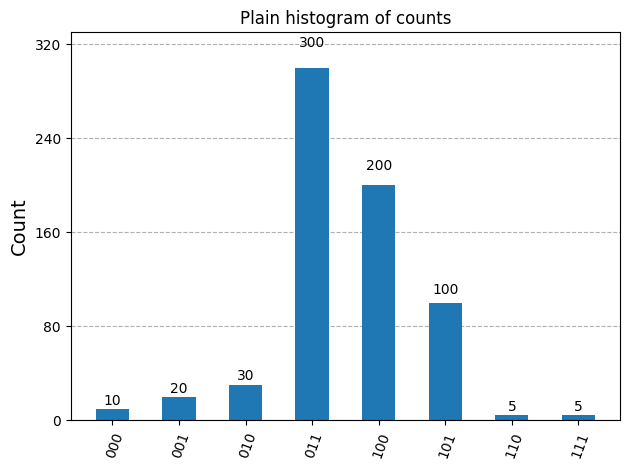

In [6]:
counts = {"000": 10, "001": 20, "010": 30, "011": 300, "100": 200, "101": 100, "110": 5, "111": 5}
plot_histogram(counts, title="Plain histogram of counts")

In [7]:
# Evidence for the table above: read the y-label and bar labels from the figure itself
def info(tag, fig):
    ax = fig.axes[0]
    print(f"{tag:<26} ylabel={ax.get_ylabel()!r:<20} x={[t.get_text() for t in ax.get_xticklabels()]}  bars={[t.get_text() for t in ax.texts]}")

info("counts (ints)",        plot_histogram(counts))
info("probabilities (floats)", plot_histogram({k: v / 670 for k, v in counts.items()}))
plt.close("all")

counts (ints)              ylabel='Count'              x=['000', '001', '010', '011', '100', '101', '110', '111']  bars=['10', '20', '30', '300', '200', '100', '5', '5']
probabilities (floats)     ylabel='Quasi-probability'  x=['000', '001', '010', '011', '100', '101', '110', '111']  bars=['0.015', '0.03', '0.045', '0.448', '0.299', '0.149', '0.007', '0.007']


### 3.1 `number_to_keep` — hides data!
It keeps the **k largest** outcomes and **sums everything else into `rest`**. The total is preserved, but you can no longer see the small outcomes.

number_to_keep=3           ylabel='Count'              x=['011', '100', '101', 'rest']  bars=['300', '200', '100', '70']
total preserved: 670 = 300 + 200 + 100 + rest(70)


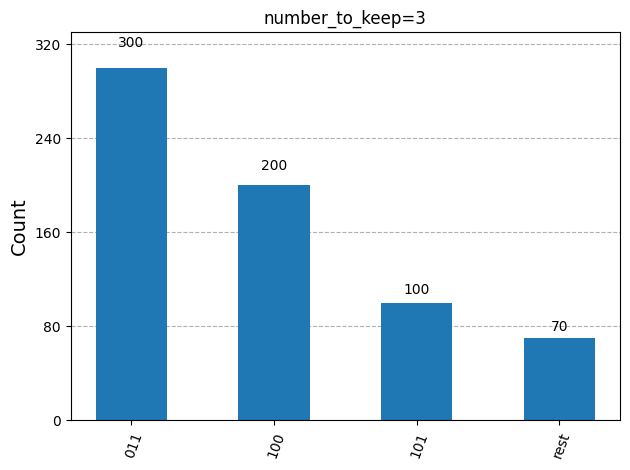

In [8]:
fig = plot_histogram(counts, number_to_keep=3, title="number_to_keep=3")
info("number_to_keep=3", fig)
print("total preserved:", sum(counts.values()), "= 300 + 200 + 100 + rest(70)")
fig

### 3.2 `sort`

In [9]:
for s in ["asc", "desc", "value", "value_desc"]:
    info(f"sort={s!r}", plot_histogram(counts, sort=s))
info("sort='hamming', target='011'", plot_histogram(counts, sort="hamming", target_string="011"))
plt.close("all")
print("\nNote (observed in the installed Qiskit): for a single dataset 'desc'/'value_desc' did not visibly reverse")
print("the order produced by 'asc'/'value'. The documented meaning is asc/desc; always LOOK at the figure.")

sort='asc'                 ylabel='Count'              x=['000', '001', '010', '011', '100', '101', '110', '111']  bars=['10', '20', '30', '300', '200', '100', '5', '5']
sort='desc'                ylabel='Count'              x=['000', '001', '010', '011', '100', '101', '110', '111']  bars=['10', '20', '30', '300', '200', '100', '5', '5']


sort='value'               ylabel='Count'              x=['110', '111', '000', '001', '010', '101', '100', '011']  bars=['5', '5', '10', '20', '30', '100', '200', '300']
sort='value_desc'          ylabel='Count'              x=['110', '111', '000', '001', '010', '101', '100', '011']  bars=['5', '5', '10', '20', '30', '100', '200', '300']


sort='hamming', target='011' ylabel='Count'              x=['011', '001', '010', '111', '000', '101', '110', '100']  bars=['300', '20', '30', '5', '10', '100', '5', '200']

Note (observed in the installed Qiskit): for a single dataset 'desc'/'value_desc' did not visibly reverse
the order produced by 'asc'/'value'. The documented meaning is asc/desc; always LOOK at the figure.


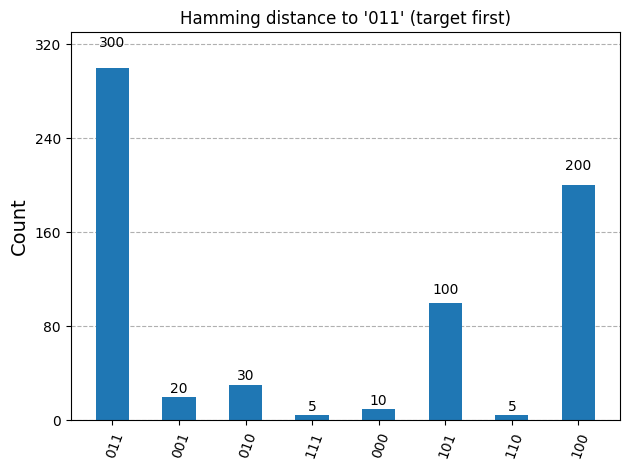

In [10]:
# hamming: the target bar comes first, then outcomes ordered by number of differing bits
plot_histogram(counts, sort="hamming", target_string="011", title="Hamming distance to '011' (target first)")

### 3.3 Comparing several experiments: `legend`, `color`
When you pass a list of dicts, bars are drawn side by side. **Bars are directly comparable only if the datasets have the same number of shots** — otherwise compare probabilities.

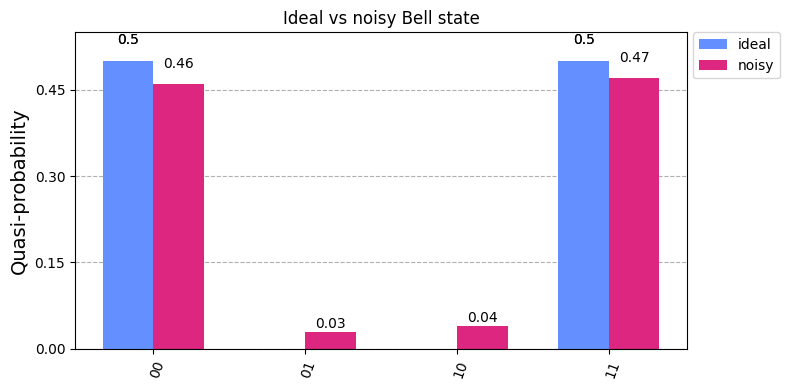

In [11]:
ideal = {"00": 0.5, "11": 0.5}
noisy = {"00": 0.46, "01": 0.03, "10": 0.04, "11": 0.47}
plot_histogram([ideal, noisy], legend=["ideal", "noisy"], color=["#648FFF", "#DC267F"],
               bar_labels=True, title="Ideal vs noisy Bell state", figsize=(8, 4))

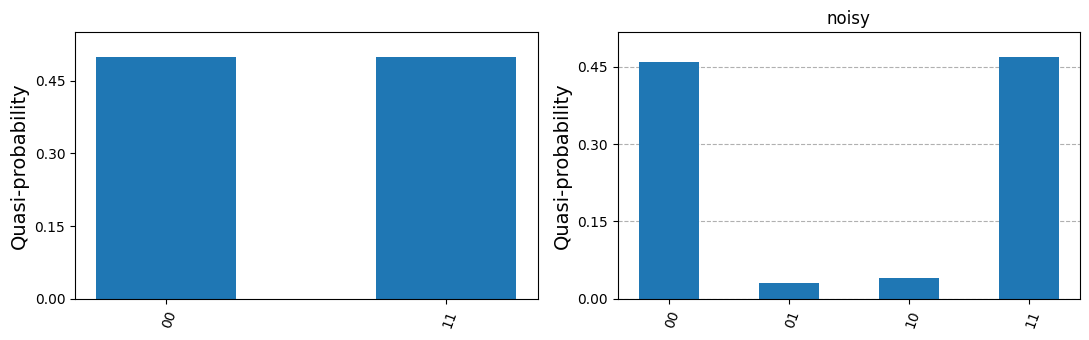

In [12]:
# Embed into your own axes (to build multi-panel figures) and save
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_histogram(ideal, ax=axes[0], title="ideal", bar_labels=False)
plot_histogram(noisy, ax=axes[1], title="noisy", bar_labels=False)
fig.tight_layout()
display(fig)
plt.close("all")

---
## 4 · What the bars estimate: exact probabilities vs finite shots

Measuring $N$ times gives an *estimate* $\hat p=k/N$ of each outcome probability $p$ with **standard error**

$$\sigma_{\hat p}=\sqrt{\frac{p(1-p)}{N}} .$$

The error shrinks like $1/\sqrt N$: to halve it you need **4×** the shots. Below we sample the same Bell-like state with 10, 100, 1000 and 10 000 shots and compare with the exact distribution.

exact: {'00': 0.7, '11': 0.3}


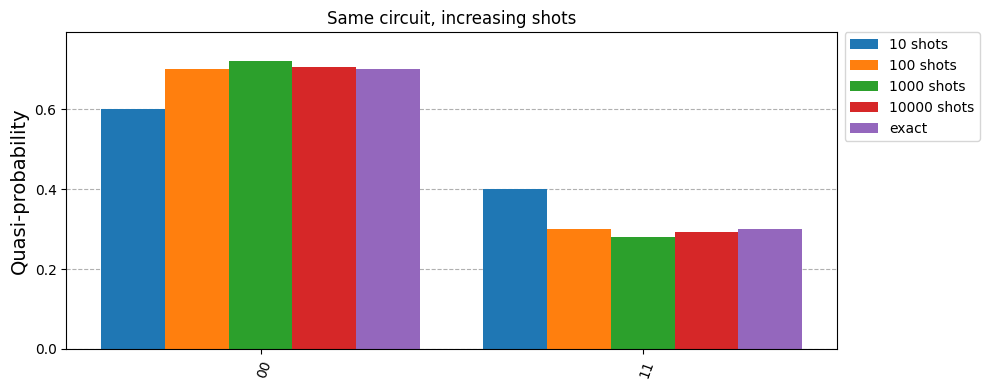

In [13]:
qc = QuantumCircuit(2, 2)
qc.ry(2 * np.arcsin(np.sqrt(0.3)), 0)          # qubit 0: P(1) = 0.3
qc.cx(0, 1)
exact = Statevector(qc.remove_final_measurements(inplace=False)).probabilities_dict()
print("exact:", {str(k): round(float(v), 3) for k, v in exact.items()})

qc.measure([0, 1], [0, 1])
datasets, labels = [], []
for shots in (10, 100, 1000, 10000):
    cts = StatevectorSampler(seed=shots).run([qc], shots=shots).result()[0].data.c.get_counts()
    datasets.append({k: v / shots for k, v in cts.items()})
    labels.append(f"{shots} shots")
datasets.append({k: float(v) for k, v in exact.items()}); labels.append("exact")
plot_histogram(datasets, legend=labels, figsize=(10, 4), bar_labels=False, title="Same circuit, increasing shots")

In [14]:
p = 0.3
print(f"{'shots':>7} | {'std. error of p̂(11)':>20} | {'observed |p̂ - p|':>18}")
for shots in (10, 100, 1000, 10000):
    cts = StatevectorSampler(seed=shots).run([qc], shots=shots).result()[0].data.c.get_counts()
    phat = cts.get("11", 0) / shots
    print(f"{shots:>7} | {np.sqrt(p * (1 - p) / shots):>20.4f} | {abs(phat - p):>18.4f}")

  shots | std. error of p̂(11) |  observed |p̂ - p|
     10 |               0.1449 |             0.1000
    100 |               0.0458 |             0.0000
   1000 |               0.0145 |             0.0210
  10000 |               0.0046 |             0.0064


---
## 5 · Measuring in a different basis (link to Task 1.1)

Hardware measures in the **Z basis**. To measure Pauli $X$ or $Y$ you rotate first (`H` for X; `Sdg`, `H` for Y). The *same state* then gives completely different histograms. We prepare $|{+i}\rangle=\frac{|0\rangle+i|1\rangle}{\sqrt2}$ (the $+1$ eigenstate of $Y$):

<X>, <Y>, <Z> = [0.0, 1.0, 0.0]


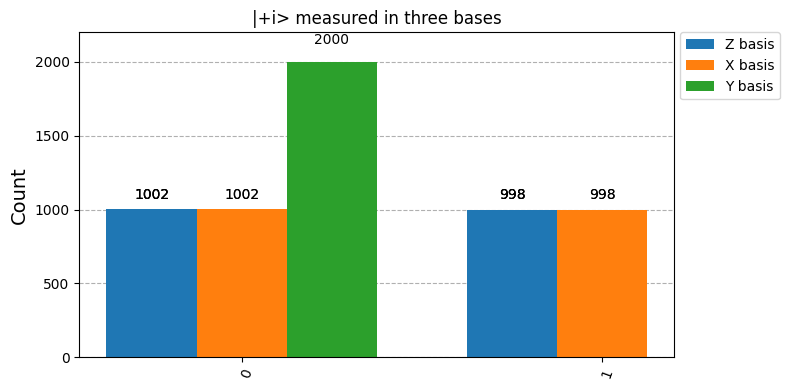

In [15]:
def measured_in(basis):
    qc = QuantumCircuit(1, 1)
    qc.h(0); qc.s(0)                    # prepare |+i>
    if basis == "X":
        qc.h(0)
    elif basis == "Y":
        qc.sdg(0); qc.h(0)
    qc.measure(0, 0)
    return qc

results = {}
for b in "ZXY":
    results[f"{b} basis"] = StatevectorSampler(seed=1).run([measured_in(b)], shots=2000).result()[0].data.c.get_counts()
psi = Statevector.from_label("r")
print("<X>, <Y>, <Z> =", [round(float(psi.expectation_value(Pauli(c)).real), 3) for c in "XYZ"])
plot_histogram(list(results.values()), legend=list(results.keys()), figsize=(8, 4), title="|+i> measured in three bases")

Z and X give 50/50 (expectation 0 → equal outcomes), Y gives **all zeros** (expectation +1). This is exactly $\Pr(0)=(1+\langle P\rangle)/2$ from Task 1.1.

---
## 6 · Mid-circuit measurement and classical feedforward (dynamic circuits)

The study guide's *Classical feedforward and control flow* page is the reference for this task: you can **measure in the middle** of a circuit and **act on the result** with four constructs, each a `QuantumCircuit` method returning a **context manager** (use with `with`):

| Construct | Method | Idea |
|---|---|---|
| If / else | `qc.if_test((bit_or_register, value))` | run the block if the condition holds; `as else_:` + `with else_:` adds an else |
| Switch | `qc.switch(target)` + `case(...)` | many branches; `case.DEFAULT`; **no fall-through** |
| For loop | `qc.for_loop(range(k))` | repeat a block a fixed number of times |
| While loop | `qc.while_loop((target, value))` | repeat while the condition holds |

(Task 3.1 builds these in depth; here we focus on **how they are drawn and measured**.)

### 6.1 If / else

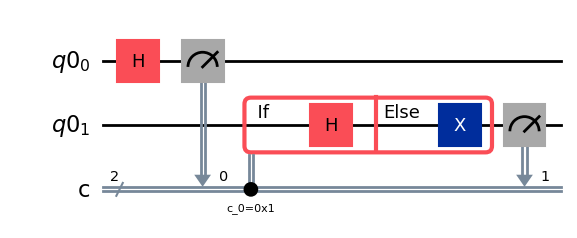

In [16]:
qubits = QuantumRegister(2); clbits = ClassicalRegister(2, "c")
circ = QuantumCircuit(qubits, clbits)
q0, q1 = qubits; c0, c1 = clbits

circ.h(q0)
circ.measure(q0, c0)
with circ.if_test((c0, 1)) as else_:
    circ.h(q1)
with else_:
    circ.x(q1)
circ.measure(q1, c1)
circ.draw("mpl")

**How to read it:** the red box is the `If` / `Else` block; the condition sits on the classical wire — a **solid dot means "equal to 1"**, an **outlined dot means "equal to 0"**; the label (e.g. `c_0=0x1`) shows the bit and the value in hex.

### 6.2 Running it — and a gotcha about *which simulator*
The reference `StatevectorSampler` **cannot execute control flow**. Use **Aer's** `SamplerV2` (or real hardware).

StatevectorSampler -> QiskitError : 'StatevectorSampler cannot handle ControlFlowOp'



AerSamplerV2 -> {'01': 1000, '11': 1005, '10': 1995}


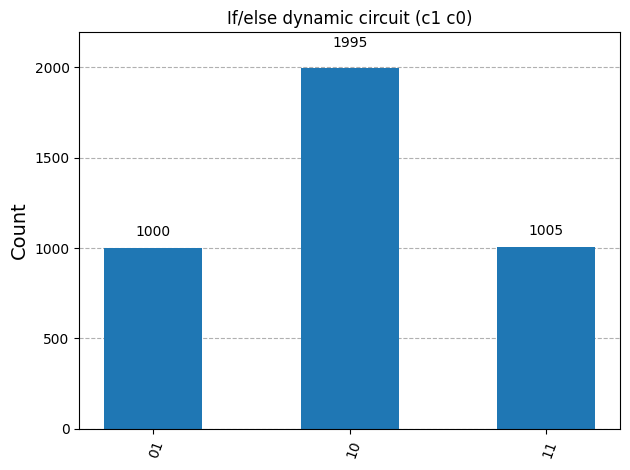

In [17]:
try:
    StatevectorSampler().run([circ], shots=10).result()
except Exception as e:
    print("StatevectorSampler ->", type(e).__name__, ":", e)

counts = AerSampler(seed=3).run([circ], shots=4000).result()[0].data.c.get_counts()
print("\nAerSamplerV2 ->", counts)
plot_histogram(counts, title="If/else dynamic circuit (c1 c0)")

Interpretation (key = `c1 c0`): if the first measurement gave 0 → `X` on q1 → c1 = 1 → keys `10`. If it gave 1 → `H` on q1 → c1 is random → keys `01` and `11`. So `10` appears ≈ 50 %, and `01`, `11` ≈ 25 % each — matching the example output in the guide.

### 6.3 Conditioning on a whole register, and `switch`

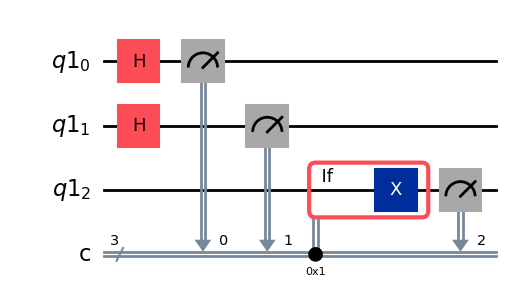

counts: {'000': 975, '011': 1006, '101': 1000, '010': 1019} 
 -> the X on q2 fires only for '001' (becoming '101'); '001' itself never appears: True


In [18]:
qubits = QuantumRegister(3); clbits = ClassicalRegister(3, "c")
reg_cond = QuantumCircuit(qubits, clbits)
reg_cond.h([0, 1])
reg_cond.measure(0, clbits[0]); reg_cond.measure(1, clbits[1])
with reg_cond.if_test((clbits, 0b001)):          # whole register must equal 001 (c2=0, c1=0, c0=1)
    reg_cond.x(2)
reg_cond.measure(2, clbits[2])
display(reg_cond.draw("mpl"))

c = AerSampler(seed=1).run([reg_cond], shots=4000).result()[0].data.c.get_counts()
print("counts:", c, "\n -> the X on q2 fires only for '001' (becoming '101'); '001' itself never appears:", "001" not in c)

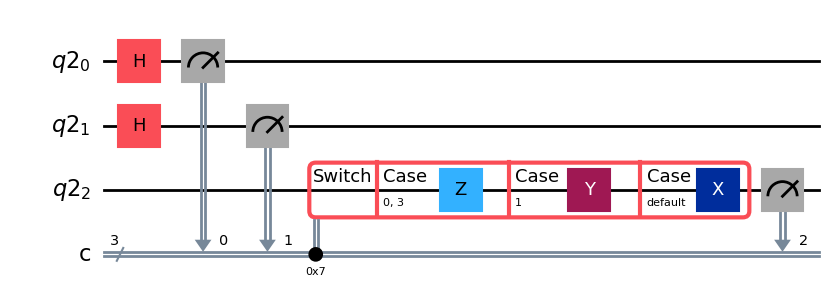

In [19]:
qubits = QuantumRegister(3); clbits = ClassicalRegister(3, "c")
sw = QuantumCircuit(qubits, clbits)
sw.h([0, 1])
sw.measure(0, clbits[0]); sw.measure(1, clbits[1])
with sw.switch(clbits) as case:
    with case(0b000, 0b011):        # one branch can handle several values
        sw.z(2)
    with case(0b001):
        sw.y(2)
    with case(case.DEFAULT):        # everything else; exactly one block runs (no fall-through)
        sw.x(2)
sw.measure(2, clbits[2])
sw.draw("mpl")

### 6.4 Loops — drawn as boxes

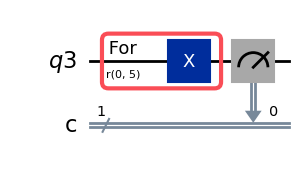

5 X gates → odd → qubit ends in |1>: {'1': 200}


In [20]:
qubits = QuantumRegister(1); clbits = ClassicalRegister(1, "c")
lp = QuantumCircuit(qubits, clbits)
with lp.for_loop(range(5)):
    lp.x(0)
lp.measure(0, 0)
display(lp.draw("mpl"))
print("5 X gates → odd → qubit ends in |1>:",
      AerSampler(seed=1).run([lp], shots=200).result()[0].data.c.get_counts())

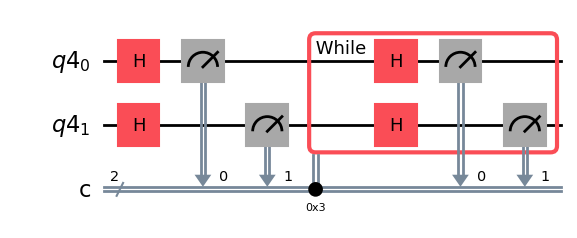

the loop re-draws until the outcome is not 11: {'00': 990, '01': 1002, '10': 1008}


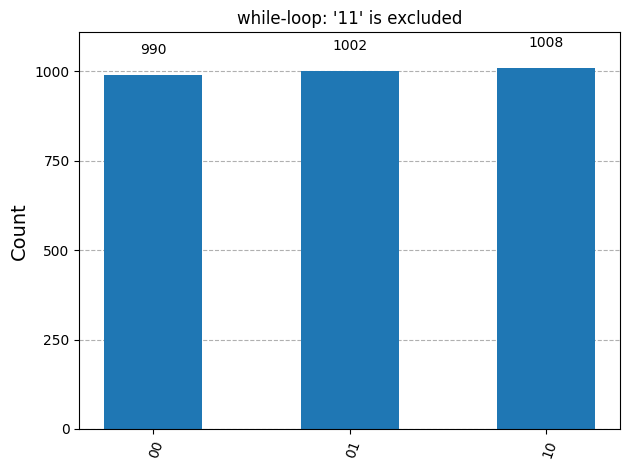

In [21]:
qubits = QuantumRegister(2); clbits = ClassicalRegister(2, "c")
wl = QuantumCircuit(qubits, clbits)
wl.h([0, 1]); wl.measure(0, clbits[0]); wl.measure(1, clbits[1])
with wl.while_loop((clbits, 0b11)):          # repeat while both measured bits are 1
    wl.h([0, 1]); wl.measure(0, clbits[0]); wl.measure(1, clbits[1])
display(wl.draw("mpl"))
cts = AerSampler(seed=2).run([wl], shots=3000).result()[0].data.c.get_counts()
print("the loop re-draws until the outcome is not 11:", cts)
plot_histogram(cts, title="while-loop: '11' is excluded")

---
## 7 · Where the measurements run: `plot_gate_map` and friends

The study guide lists `plot_gate_map` under this task. It draws a **device's qubit layout and coupling graph** — i.e. *which* physical qubits exist, which pairs can run two-qubit gates, and (with colours) how good each qubit's **readout** is.

```python
plot_gate_map(backend, figsize=None, plot_directed=False, label_qubits=True, qubit_size=None, line_width=4,
              font_size=None, qubit_color=None, qubit_labels=None, line_color=None, font_color='white',
              ax=None, filename=None, qubit_coordinates=None)
```

| Parameter | Meaning |
|---|---|
| `backend` | a backend object — a real one from `QiskitRuntimeService`, or a fake/generic one for offline use |
| `plot_directed` | draw **arrows** for directional two-qubit gates instead of plain lines |
| `label_qubits`, `qubit_labels` | show / customise qubit numbers |
| `qubit_color` | **list of colours, one per qubit** (e.g. colour by error rate) |
| `line_color` | list of colours, one per **edge** |
| `qubit_size`, `line_width`, `font_size`, `font_color` | sizes |
| `qubit_coordinates` | explicit `[row, col]` positions (needed for devices Qiskit has no layout for) |

On real hardware you would write:

```python
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService()                 # needs your saved IBM Quantum credentials
backend = service.least_busy(operational=True, simulator=False)
plot_gate_map(backend)
```

Here we use `GenericBackendV2` — a **local, fake** 7-qubit device with the same *shape* as IBM's small "H" chips, with randomised calibration data — so everything runs offline.

num_qubits: 7 | basis gates: ['cx', 'id', 'rz', 'sx', 'x', 'reset', 'delay', 'measure']


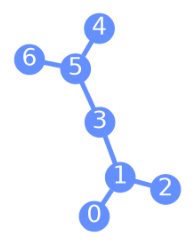

In [22]:
H_shape = [[0, 1], [1, 0], [1, 2], [2, 1], [1, 3], [3, 1], [3, 5], [5, 3], [4, 5], [5, 4], [5, 6], [6, 5]]
backend = GenericBackendV2(num_qubits=7, coupling_map=H_shape, seed=3)
print("num_qubits:", backend.num_qubits, "| basis gates:", backend.operation_names)
plot_gate_map(backend)

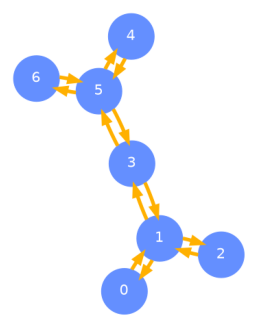

In [23]:
plot_gate_map(backend, plot_directed=True, qubit_color=["#648FFF"] * 7, line_color=["#FFB000"] * 12,
              qubit_size=60, font_size=16, figsize=(5, 4))

### 7.1 Colour qubits by **readout error** (a measurement-quality map)
Every backend's `target` stores per-qubit **measurement** error. Colouring `plot_gate_map` by it shows at a glance where *your measurements* will be most reliable.

{0: 0.0035, 1: 0.0034, 2: 0.003, 3: 0.0033, 4: 0.0028, 5: 0.0025, 6: 0.0024}
worst readout: qubit 0 (error 0.0035) — drawn in pink


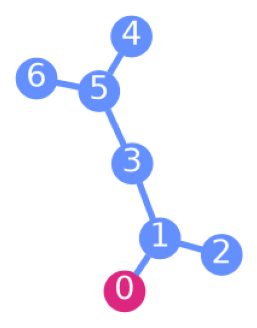

In [24]:
readout = {q: backend.target["measure"][(q,)].error for q in range(backend.num_qubits)}
print({q: round(e, 4) for q, e in readout.items()})

worst = max(readout, key=readout.get)
colors = ["#DC267F" if q == worst else "#648FFF" for q in range(backend.num_qubits)]
print(f"worst readout: qubit {worst} (error {readout[worst]:.4f}) — drawn in pink")
plot_gate_map(backend, qubit_color=colors, figsize=(5, 4))

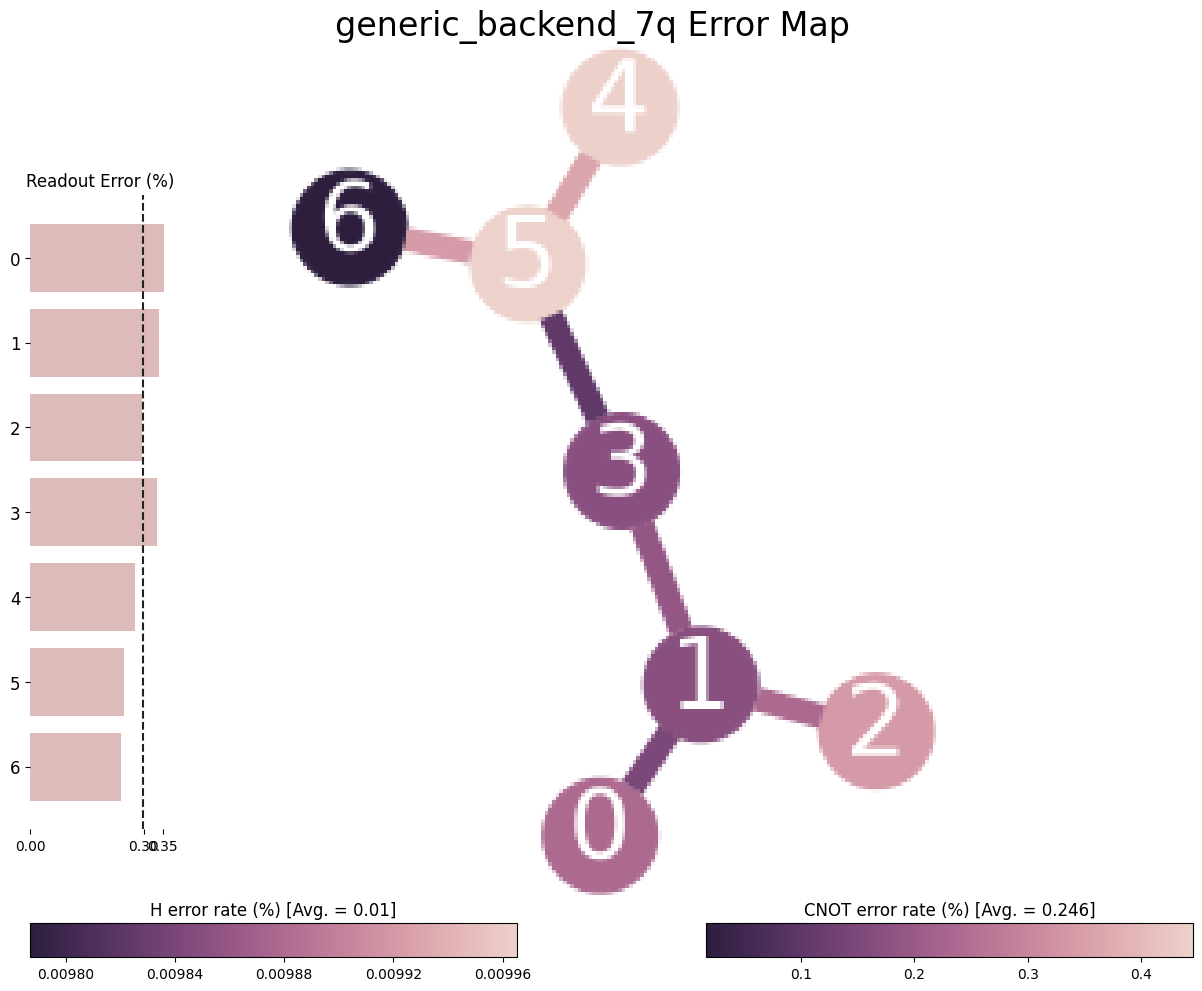

In [25]:
# plot_error_map: ONE figure with single-qubit gate error, readout error, and two-qubit error per link
plot_error_map(backend)

### 7.2 `plot_coupling_map` — a device you describe yourself
Same drawing, but **from plain lists** — no backend needed. Handy for hypothetical devices and teaching.

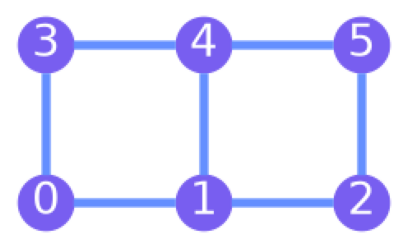

In [26]:
# A 2x3 grid: coordinates are [row, col]; coupling_map lists directed pairs
coords = [[0, 0], [0, 1], [0, 2], [1, 0], [1, 1], [1, 2]]
edges = [[0, 1], [1, 2], [3, 4], [4, 5], [0, 3], [1, 4], [2, 5]]
plot_coupling_map(6, coords, edges, figsize=(5, 3.5), qubit_color=["#785EF0"] * 6)

### 7.3 `plot_circuit_layout` — where did my qubits end up?
After transpilation each **virtual** qubit sits on a **physical** qubit. `plot_circuit_layout(circuit, backend, view="virtual"|"physical")` draws the device and marks the physical qubits your circuit actually uses (here: dark, labelled nodes; with `view="virtual"` they are labelled by your *virtual* qubit numbers instead).

qubits used by the measurements: [3, 5]


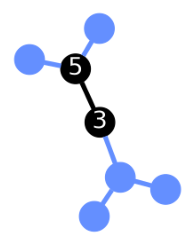

In [27]:
bell = QuantumCircuit(2, 2); bell.h(0); bell.cx(0, 1); bell.measure([0, 1], [0, 1])
tc = transpile(bell, backend, initial_layout=[3, 5], seed_transpiler=1)     # force physical qubits 3 and 5
print("qubits used by the measurements:", sorted({tc.find_bit(q).index for i in tc.data if i.operation.name == "measure" for q in i.qubits}))
plot_circuit_layout(tc, backend, view="physical")

---
## 8 · Gotchas checklist

1. **Classical bit 0 is the rightmost character** of a counts key; *you* choose which classical bit each qubit writes to.
2. **The register name is the attribute name:** `QuantumCircuit(n, n)` → `data.c`; `measure_all()` → `data.meas`; a register called `alpha` → `data.alpha`. Several registers → several `BitArray`s; glue them with `join_data([...])` (first name listed ends on the right).
3. **Ints plot as counts, floats as (quasi-)probabilities;** compare datasets only if shot counts are equal (or normalise).
4. **`number_to_keep=k` hides data:** keeps the *k largest* outcomes, merges the rest into one `rest` bar.
5. **`sort='hamming'` needs `target_string`;** and `asc/desc` variants may not behave as you expect — look at the picture.
6. **10 shots tell you almost nothing:** standard error $\sqrt{p(1-p)/N}$, $1/\sqrt N$ convergence.
7. **`StatevectorSampler` cannot run control flow** (`ControlFlowOp`); use Aer's `SamplerV2` or hardware.
8. **A solid classical dot = condition on 1; outlined = on 0.** Register conditions are written in hex (`0x1`).
9. **`plot_gate_map` needs a backend** (real or fake) — or use `plot_coupling_map` with explicit lists. `qubit_color` takes **one colour per qubit**, `line_color` **one per edge**.
10. **Mid-circuit measurement is not the same as final measurement** — measured bits can steer later gates (feedforward); hardware support has limits (see the guide's *Execute dynamic circuits* link).
11. **`measure_all()` adds a barrier and a new register;** `measure_all(add_bits=False)` re-uses existing bits.

---
## 9 · Exercises

### Exercise 1 — predict the key
A 3-qubit circuit does: `x(1)`, then `measure(0 → c2)`, `measure(1 → c0)`, `measure(2 → c1)` (3 classical bits, register `c`). **Without running it**, what single counts key (bit-string) will appear with certainty? Return the string.

In [28]:
def exercise_1():
    # TODO: return the bit-string key (c2 c1 c0) as a str
    return None

ans1 = exercise_1()

In [29]:
def check_1(key):
    if key is None: return _todo("Exercise 1")
    qc = QuantumCircuit(3, 3)
    qc.x(1)
    qc.measure(0, 2); qc.measure(1, 0); qc.measure(2, 1)
    truth = StatevectorSampler(seed=1).run([qc], shots=50).result()[0].data.c.get_counts()
    assert list(truth) == [key], f"actual counts are {truth}; you answered {key!r}"
    print("✅ Exercise 1 passed — you can read measurement wiring.")
check_1(ans1)

⏳ Exercise 1: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 2 — what does `number_to_keep` show?
Write `rest_summary(counts, k)` that returns a dict of the **k largest** outcomes plus one entry `"rest"` with the sum of all the others — exactly what `plot_histogram(counts, number_to_keep=k)` displays. (If nothing is left over, omit `"rest"`.)

In [30]:
def rest_summary(counts, k):
    # TODO
    return None

In [31]:
def check_2():
    c = {"000": 10, "001": 20, "010": 30, "011": 300, "100": 200, "101": 100, "110": 5, "111": 5}
    got = rest_summary(c, 3)
    if got is None: return _todo("Exercise 2")
    assert got == {"011": 300, "100": 200, "101": 100, "rest": 70}, f"got {got}"
    assert rest_summary({"0": 5, "1": 3}, 2) == {"0": 5, "1": 3}, "no 'rest' when nothing is left over"
    # cross-check against the real plot
    fig = plot_histogram(c, number_to_keep=3)
    shown = {t.get_text() for t in fig.axes[0].get_xticklabels()}
    assert shown == set(got), f"plot shows {shown}"
    plt.close("all")
    print("✅ Exercise 2 passed — and it matches what plot_histogram really draws.")
check_2()

⏳ Exercise 2: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 3 — measure in the Y basis
`prep` prepares a state on 1 qubit. Return a **new circuit** = `prep` followed by the right basis change and a **measurement into classical bit 0**, so that the histogram reads out the **Y** observable.

In [32]:
prep = QuantumCircuit(1, 1)
prep.h(0); prep.s(0)                     # |+i>

def exercise_3():
    # TODO: return prep + basis change for Y + measure(0, 0)
    return None

ans3 = exercise_3()

In [33]:
def check_3(qc):
    if qc is None: return _todo("Exercise 3")
    assert qc.data[-1].operation.name == "measure", "the circuit must end with a measurement"
    body = qc.remove_final_measurements(inplace=False)
    p = Statevector(body).probabilities()
    assert np.allclose(p, [1, 0], atol=1e-8), f"P(0),P(1) = {p.round(3)}; |+i> in the Y basis must give outcome 0 with certainty"
    print("✅ Exercise 3 passed — Y-basis measurement of |+i> is deterministic (<Y> = +1).")
check_3(ans3)

⏳ Exercise 3: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 4 — feedforward
Build a 2-qubit circuit (register `c`, 2 bits): `H` on qubit 0, **measure** it into `c[0]`, **if** `c[0]` is 1 then apply `X` to qubit 1, finally measure qubit 1 into `c[1]`. The outcomes `01` and `10` must be impossible (qubit 1 ends up equal to qubit 0's result).

In [34]:
def exercise_4():
    # TODO: build the dynamic circuit described above
    return None

ans4 = exercise_4()

In [35]:
def check_4(qc):
    if qc is None: return _todo("Exercise 4")
    assert "if_else" in qc.count_ops(), "the circuit must contain an if_test (if_else) block"
    counts = AerSampler(seed=9).run([qc], shots=3000).result()[0].data.c.get_counts()
    assert set(counts) == {"00", "11"}, f"only '00' and '11' may occur, got {counts}"
    assert min(counts.values()) > 1200, f"both outcomes should be near 50%, got {counts}"
    print("✅ Exercise 4 passed —", counts)
    display(plot_histogram(counts, title="Exercise 4: feedforward copies the first outcome"))
check_4(ans4)

⏳ Exercise 4: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 5 — how many shots?
You estimate a probability $p\approx0.5$ and want its **standard error to be at most 0.01**. What is the **smallest integer number of shots** $N$ that guarantees it for $p=0.5$? Return an `int`.

In [36]:
def exercise_5():
    # TODO: smallest integer N with sqrt(p(1-p)/N) <= 0.01 for p = 0.5
    return None

ans5 = exercise_5()

In [37]:
def check_5(N):
    if N is None: return _todo("Exercise 5")
    se = lambda m: np.sqrt(0.25 / m)
    assert se(N) <= 0.01 + 1e-12 and se(N - 1) > 0.01, f"N={N}: std err {se(N):.5f}; is it the SMALLEST such integer?"
    print(f"✅ Exercise 5 passed — N = {N} shots gives standard error {se(N):.4f}; 4x more shots would halve it.")
check_5(ans5)

⏳ Exercise 5: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 6 — find the worst qubit
Write `worst_readout_qubit(backend)` returning the **index of the physical qubit with the largest readout (measurement) error** according to `backend.target`.

In [38]:
def worst_readout_qubit(backend):
    # TODO
    return None

In [39]:
def check_6():
    got = worst_readout_qubit(backend)
    if got is None: return _todo("Exercise 6")
    errs = [backend.target["measure"][(q,)].error for q in range(backend.num_qubits)]
    assert got == int(np.argmax(errs)), f"expected qubit {int(np.argmax(errs))}, got {got}"
    print(f"✅ Exercise 6 passed — physical qubit {got} has the worst readout; avoid it with initial_layout.")
check_6()

⏳ Exercise 6: not attempted yet — fill in the TODO above and re-run this cell.


### Playground
- Take Exercise 4 and replace the `if_test` by a `switch` with a default branch. Do the counts change?
- Draw a 3-qubit GHZ circuit with `measure_all()`; plot the histogram with `sort="hamming"` and `target_string="000"`.
- Change `number_to_keep` from 1 to 8 on the same data and watch the `rest` bar vanish.
- Colour `plot_gate_map` by *two-qubit* error instead of readout error (look at `backend.target["cx"]`).

---
## 10 · Exam-style questions

**Q1.** A circuit has registers `QuantumRegister(2,"q")` and `ClassicalRegister(2,"out")`. How do you get the counts from a `Sampler` PUB result `pub`?
- A) `pub.data.c.get_counts()`  B) `pub.data.out.get_counts()`  C) `pub.counts`  D) `pub.get_counts("out")`

<details><summary>Answer</summary>

**B.** The register name is the attribute on `DataBin`.
</details>

**Q2.** After `qc.measure_all()` on a circuit with no classical bits, the register holding the results is called:
- A) `c`  B) `m`  C) `meas`  D) `creg`

<details><summary>Answer</summary>

**C.**
</details>

**Q3.** `plot_histogram(counts, number_to_keep=2)` on 8 outcomes shows:
- A) the first two outcomes alphabetically  B) the two largest outcomes plus a `rest` bar  C) only two bars, nothing else  D) an error

<details><summary>Answer</summary>

**B.**
</details>

**Q4.** The y-axis of `plot_histogram` on a dict with **integer** values is labelled:
- A) `Probability`  B) `Count`  C) `Quasi-probability`  D) `Shots`

<details><summary>Answer</summary>

**B.** Floats give `Quasi-probability`.
</details>

**Q5.** Which constructs does Qiskit provide for classical control flow?
- A) `if_test`, `switch`, `for_loop`, `while_loop`  B) `c_if` only  C) `branch`, `repeat`  D) none — only hardware supports them

<details><summary>Answer</summary>

**A.** (`c_if` was removed.) All four are `QuantumCircuit` methods returning context managers.
</details>

**Q6.** Which simulator can execute an `if_test` circuit?
- A) `StatevectorSampler`  B) Aer's `SamplerV2` / `AerSimulator`  C) `Statevector`  D) `Operator`

<details><summary>Answer</summary>

**B.** `StatevectorSampler` raises "cannot handle ControlFlowOp".
</details>

**Q7.** In an mpl drawing of a conditioned block, a **solid** circle on a classical bit means:
- A) condition on 0  B) condition on 1  C) the bit is unused  D) the bit was reset

<details><summary>Answer</summary>

**B.**
</details>

**Q8.** Which statement is **true** of `plot_gate_map(backend, qubit_color=[...])`?
- A) the list has one colour per edge  B) one colour per qubit  C) it must be a single colour  D) it is ignored for fake backends

<details><summary>Answer</summary>

**B.** (`line_color` is the per-edge list.)
</details>

**Q9.** To estimate a probability near 0.5 with half the standard error, you need:
- A) 2× the shots  B) 4× the shots  C) 0.5× the shots  D) the same shots on better hardware

<details><summary>Answer</summary>

**B.** Standard error ∝ $1/\sqrt N$.
</details>

**Q10.** `qc.measure(0, 1); qc.measure(1, 0)` with qubit 0 in $|1\rangle$ and qubit 1 in $|0\rangle$ gives the counts key:
- A) `'01'`  B) `'10'`  C) `'11'`  D) `'00'`

<details><summary>Answer</summary>

**B.** qubit 0 → c1 = 1, qubit 1 → c0 = 0, key = `c1 c0` = `10`.
</details>

---
## 11 · Solutions & explanations

In [40]:
# --- Solution 1 -----------------------------------------------------------
# X flips qubit 1 -> measured into c0 (rightmost) => c0 = 1 ; qubit 0 -> c2 = 0 ; qubit 2 -> c1 = 0
check_1("001")

✅ Exercise 1 passed — you can read measurement wiring.


In [41]:
# --- Solution 2 -----------------------------------------------------------
def rest_summary_solution(counts, k):
    top = dict(sorted(counts.items(), key=lambda kv: kv[1], reverse=True)[:k])
    leftover = sum(counts.values()) - sum(top.values())
    if leftover:
        top["rest"] = leftover
    return top

_c = {"000": 10, "001": 20, "010": 30, "011": 300, "100": 200, "101": 100, "110": 5, "111": 5}
print(rest_summary_solution(_c, 3))

{'011': 300, '100': 200, '101': 100, 'rest': 70}


In [42]:
# --- Solution 3 -----------------------------------------------------------
sol3 = prep.copy()
sol3.sdg(0)        # S† : |+i> -> |+>
sol3.h(0)          # H  : |+> -> |0>   => deterministic outcome 0 means  <Y> = +1
sol3.measure(0, 0)
check_3(sol3)

✅ Exercise 3 passed — Y-basis measurement of |+i> is deterministic (<Y> = +1).


✅ Exercise 4 passed — {'11': 1490, '00': 1510}


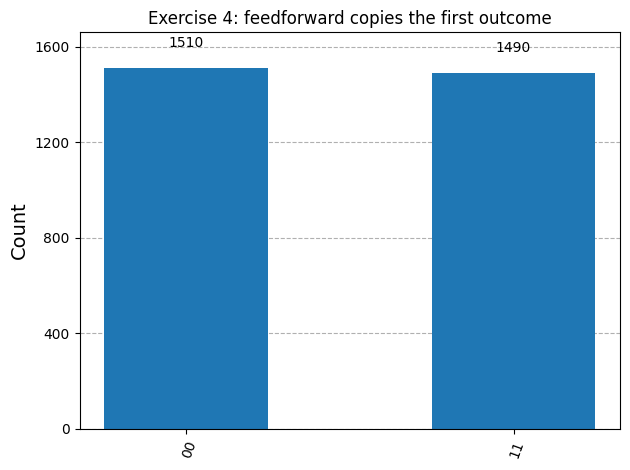

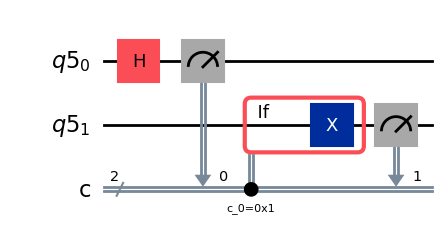

In [43]:
# --- Solution 4 -----------------------------------------------------------
q = QuantumRegister(2); c = ClassicalRegister(2, "c")
sol4 = QuantumCircuit(q, c)
sol4.h(q[0]); sol4.measure(q[0], c[0])
with sol4.if_test((c[0], 1)):
    sol4.x(q[1])
sol4.measure(q[1], c[1])
check_4(sol4)
sol4.draw("mpl")

In [44]:
# --- Solution 5 -----------------------------------------------------------
# sqrt(0.25/N) <= 0.01  <=>  N >= 0.25 / 0.0001 = 2500
check_5(2500)

✅ Exercise 5 passed — N = 2500 shots gives standard error 0.0100; 4x more shots would halve it.


In [45]:
# --- Solution 6 -----------------------------------------------------------
errs = {q: backend.target["measure"][(q,)].error for q in range(backend.num_qubits)}
sol6 = max(errs, key=errs.get)
print("worst readout qubit:", sol6, "| errors:", {q: round(e, 4) for q, e in errs.items()})

worst readout qubit: 0 | errors: {0: 0.0035, 1: 0.0034, 2: 0.003, 3: 0.0033, 4: 0.0028, 5: 0.0025, 6: 0.0024}


---
## 12 · One-page summary

- **Measurement:** `measure(q, c)`; `measure_all()` → adds barrier + register `meas`; **key = c_{k-1}…c_0**, classical bit 0 is the rightmost character.
- **Results:** `result[i].data.<register_name>` → `BitArray` → `get_counts()`, `get_int_counts()`, `get_bitstrings()`, `num_shots`; `join_data([...])` glues registers (first listed = rightmost).
- **`plot_histogram(data, figsize, color, number_to_keep, sort, target_string, legend, bar_labels, title, ax, filename)`**; ints → *Count*, floats → *Quasi-probability*; `number_to_keep=k` keeps the k largest + `rest`; `plot_distribution` is the sibling.
- **Shot noise:** $\sigma=\sqrt{p(1-p)/N}$ → quadruple the shots to halve the error.
- **Other bases:** X needs `H`; Y needs `Sdg`,`H`; $\Pr(0)=(1+\langle P\rangle)/2$.
- **Dynamic circuits:** `if_test`, `switch`, `for_loop`, `while_loop` (context managers); solid dot = condition on 1; run on **Aer** (not `StatevectorSampler`).
- **Hardware maps:** `plot_gate_map(backend, plot_directed, qubit_color[per qubit], line_color[per edge], …)`, `plot_coupling_map(num_qubits, coords, edges)`, `plot_error_map`, `plot_circuit_layout(circ, backend, view)`.
- **Next:** Task 2.3 — visualising quantum **states** (Bloch spheres and the Q-sphere).